# Project Business Statistics: E-news Express


## Define Problem Statement and Objectives

## Import all the necessary libraries

In [ ]:
# Installing the libraries with the specified version.
!pip install numpy==1.25.2 pandas==1.5.3 matplotlib==3.7.1 seaborn==0.13.1 scipy==1.11.4 -q --user

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.4/60.4 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.2/18.2 MB 43.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 59.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 68.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 294.8/294.8 kB 19.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 36.4/36.4 MB 17.5 MB/s eta 0:00:00
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 1.5.3 which is incompatible.
plotnine 0.14.5 requires matplotlib>=3.8.0, but you have matplotlib 3.7.1 which is incompatible.
plotnine 0.14.5 requires pandas>=2.2.0, but

**Note**: *After running the above cell, kindly restart the notebook kernel and run all cells sequentially from the start again.*

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
#Restrict float values to 3 decimal places
pd.set_option('display.float_format', lambda x: '%.3f' % x)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Reading the Data into a DataFrame

In [ ]:
data = pd.read_csv('/content/drive/MyDrive/Python/abtest.csv')

## Explore the dataset and extract insights using Exploratory Data Analysis

- Data Overview
  - Viewing the first and last few rows of the dataset
  - Checking the shape of the dataset
  - Getting the statistical summary for the variables
- Check for missing values
- Check for duplicates

In [ ]:
data.head()

,user_id,group,landing_page,time_spent_on_the_page,converted,language_preferred
0,546592,control,old,3.480,no,Spanish
1,546468,treatment,new,7.130,yes,English
2,546462,treatment,new,4.400,no,Spanish
3,546567,control,old,3.020,no,French
4,546459,treatment,new,4.750,yes,Spanish


In [ ]:
data.tail()

,user_id,group,landing_page,time_spent_on_the_page,converted,language_preferred
95,546446,treatment,new,5.150,no,Spanish
96,546544,control,old,6.520,yes,English
97,546472,treatment,new,7.070,yes,Spanish
98,546481,treatment,new,6.200,yes,Spanish
99,546483,treatment,new,5.860,yes,English


We can observe that we have 100 rows with unique used IDs, the landing page information, the time the user spent on the website, if they suscribed and the user's preferred language.

In [ ]:
print('There are ', data.shape[0], ' rows and ', data.shape[1], ' columns in the dataset.')

There are  100  rows and  6  columns in the dataset.


In [ ]:
data.describe()

,user_id,time_spent_on_the_page
count,100.000,100.000
mean,546517.000,5.378
std,52.296,2.378
min,546443.000,0.190
25%,546467.750,3.880
50%,546492.500,5.415
75%,546567.250,7.022
max,546592.000,10.710


The average time the users spent on the page it's 5.378 minutes, the minimum time is barely 20 seconds and the max time 10.71 minutes.

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   user_id                 100 non-null    int64  
 1   group                   100 non-null    object 
 2   landing_page            100 non-null    object 
 3   time_spent_on_the_page  100 non-null    float64
 4   converted               100 non-null    object 
 5   language_preferred      100 non-null    object 
dtypes: float64(1), int64(1), object(4)
memory usage: 4.8+ KB


It looks like the dataset is not missing values and the type of data on each column makes sense. User ID is an integer, Time spent on the page is a float and the rest of the columns are text.

In [ ]:
data['group'].unique()

array(['control', 'treatment'], dtype=object)

In [ ]:
data['landing_page'].unique()

array(['old', 'new'], dtype=object)

In [ ]:
data['converted'].unique()

array(['no', 'yes'], dtype=object)

The converted data it's in a text format, we might need to convert it into binary values for statistical tests since this is an important category.

In [ ]:
data['language_preferred'].unique()

array(['Spanish', 'English', 'French'], dtype=object)

The data from the categorical variables looks in order. There is no need to go through a missing data treatment.

### Univariate Analysis

<Axes: ylabel='time_spent_on_the_page'>

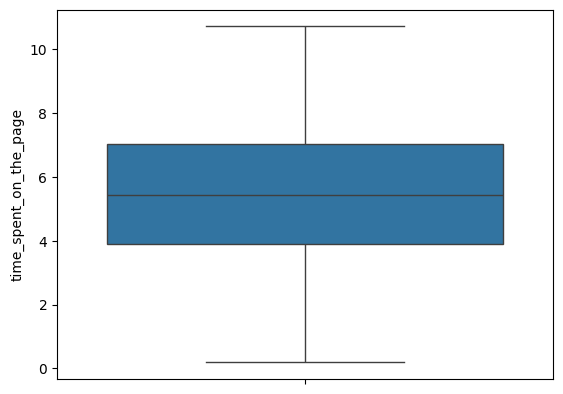

In [ ]:
sns.boxplot(data['time_spent_on_the_page'])

The median time spent is around 5-6 minutes, and the data seems to have a normal distribution.
50% of the data lies between 4 and 7 minutes.
There aren't abnormal outliers.

Text(0.5, 1.0, 'Distribution of Time Spent on the Page by Group')

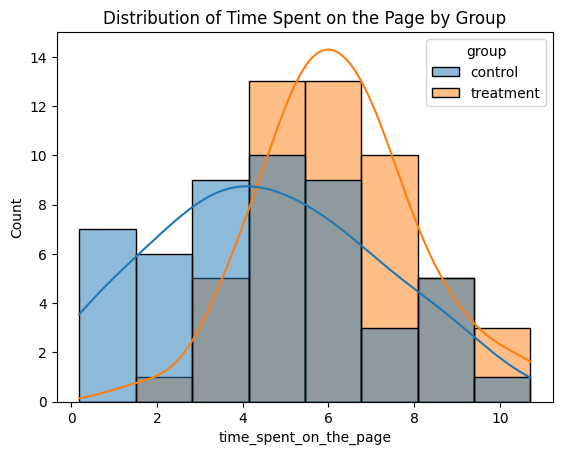

In [ ]:
sns.histplot(data=data, x='time_spent_on_the_page', hue='group', kde=True)
plt.title('Distribution of Time Spent on the Page by Group')

We can observe that treatment group has a slight right skew, peaking at around 5 to 6 minutes.
And the control group has a flatter curve peaking at 8 minutes however the flat curve suggests the time spent on the page it's less consistent.
From this chart we cand conclude that the new landing page has a positive impact on the time spent on the page, however we need to dig deeper with statistical tests.

Text(0.5, 1.0, 'Conversion Rate by Group')

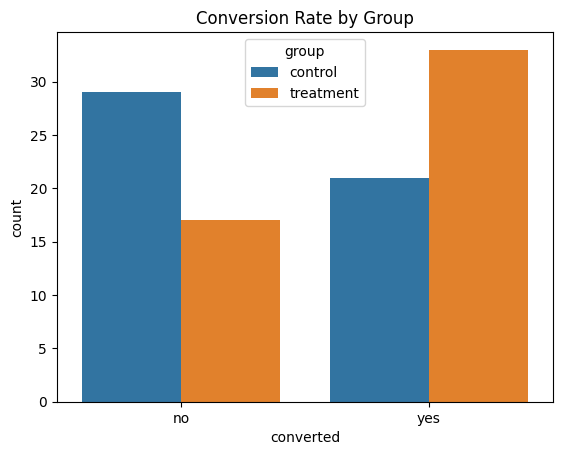

In [ ]:
sns.countplot(data=data, x='converted', hue='group')
plt.title('Conversion Rate by Group')

From this histogram we can conclude that from the control group more people didn't convert, as for the treatment group the convertion rate is higher.
This is also a green light suggesting that the new landing page improved the suscription rate.

Text(0.5, 1.0, 'Conversion Rate by Language Preference')

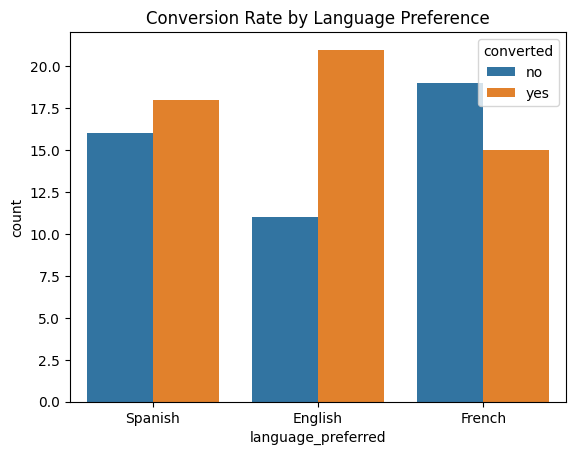

In [ ]:
sns.countplot(data=data, x='language_preferred', hue='converted')
plt.title('Conversion Rate by Language Preference')

We can observe that English speakers have the highest count of conversions.
The next higher convertion rate it's the Spanish language, but the no vs yes convertion rate is not as strong as the English language.
French language has the higest amount of non converted users and has less converted userns than not converted. The difference is not that drastical but it can indicate that something might be off with the French users perception of the website.

### Bivariate Analysis

<Axes: xlabel='group', ylabel='time_spent_on_the_page'>

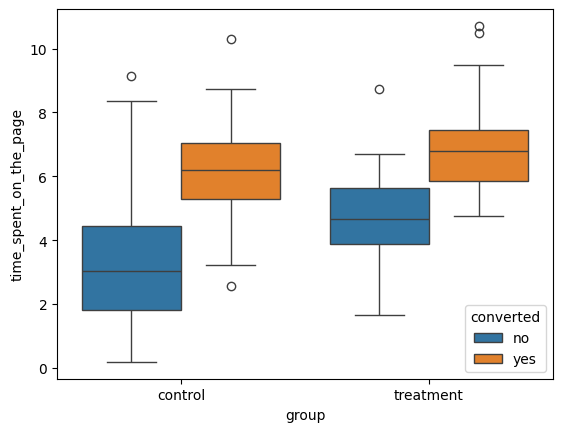

In [ ]:
sns.boxplot(data=data, x='group', y='time_spent_on_the_page', hue='converted')

From this chart we can observe that the median time spent on the page for users that converted is around 6 to 7 minutes, way more than the non converted that spent only 4 to 4 minutes.
Time spent seems positively correlated with conversion. This supports the idea that the new page keeps users interested and encourages conversion.

<Axes: xlabel='language_preferred', ylabel='time_spent_on_the_page'>

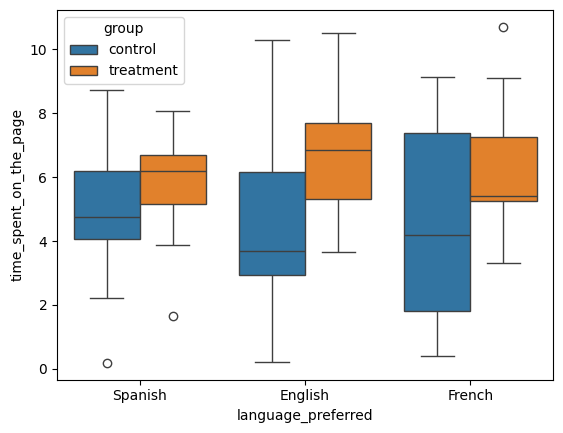

In [ ]:
sns.boxplot(data=data, x='language_preferred', y='time_spent_on_the_page', hue='group')

We can observe a small increase on the treatment group for spanish, but there's overall consistency on it's data. English has a significat time increase on the treatment group. And French is really spread with a little decrease on it's time spent on page for the treatment group.
English users benefit most from the new page in terms of time spent. French users seem to need a landing page tailored to their needs. Spanish users look consistent across both pages.

## 1. Do the users spend more time on the new landing page than the existing landing page?

### Perform Visual Analysis

In [ ]:
from scipy.stats import norm

Text(-1, 0.2, '  Do Not Reject\n        H₀')

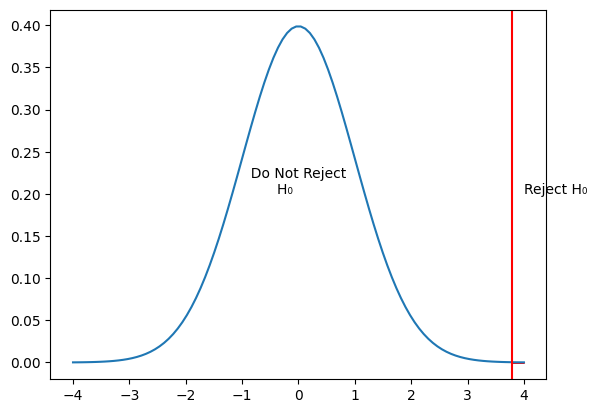

In [ ]:
x = np.linspace(-4, 4, 100)
plt.plot(x, norm.pdf(x, 0, 1))
plt.axvline(x = t_stat, c = 'r')
x1 = np.linspace(t_stat, 4, 50)
plt.fill_between(x1, norm.pdf(x1, 0, 1), color='r')
plt.annotate('Reject H₀', (4, 0.20))
plt.annotate('  Do Not Reject\n        H₀', (-1, 0.20))

### Step 1: Define the null and alternate hypotheses



*   H₀: μ1 = μ2
The mean time spent on both pages is the same.
*   Ha: μ1 ≥ μ2
The mean time spent on the new page is greater than the tme spent on the old page.

### Step 2: Select Appropriate test

Since we're comparing means between two independent groups (control and treatment) we will analize the hypothesis with an independent two-sample t-test.
Since the question asks about “greater than” we use a one-tailed test.
Assumptions:

*   Continuous data
*   Normal distribution
*   Sample size > 30
*   Independent population
*   Random sampling
*   σ unknown

Two sample problem, one tailed hypothesis, concerning population mean.

### Step 3: Decide the significance level

We will use the common 5% significance level

### Step 4: Collect and prepare data

In [ ]:
# Getting the values per group
control_times = data[data['group'] == 'control']['time_spent_on_the_page']
treatment_times = data[data['group'] == 'treatment']['time_spent_on_the_page']

### Step 5: Calculate the p-value

In [ ]:
from scipy import stats
t_stat, p_val = stats.ttest_ind(treatment_times, control_times, equal_var=False)
one_tailed_p = p_val
print("T-statistic:", t_stat)
print("One-tailed p-value:", one_tailed_p)

T-statistic: 3.7867702694199856
One-tailed p-value: 0.0001392381225166549


### Step 6: Compare the p-value with $\alpha$

In [ ]:
alpha = 0.05
if one_tailed_p < alpha:
    print("Reject the null hypothesis")
else:
    print("Fail to reject the null hypothesis")

Reject the null hypothesis


### Step 7:  Draw inference

At a 5% significance level, we reject the null hypothesis,  showing that users spend significantly more time on the new landing page than the existing one.

**A similar approach can be followed to answer the other questions.**

## 2. Is the conversion rate (the proportion of users who visit the landing page and get converted) for the new page greater than the conversion rate for the old page?

*   H₀: P1 ≤ P2  The conversion rate for the new page is smaller or equal than the old page
*   Ha: P1 > P2
The conversion rate for the new page is greater than the old page

Since we're comparing population proportions we will analize the hypothesis with a one-proportion z-test.

Assumptions:

*   Binominally distributed population
*   Independent population
*   Random sampling
*   np (50) and 1-p (50) ≥ 10 = approximate a normal distribution

One-tailed test concerning population proportions.

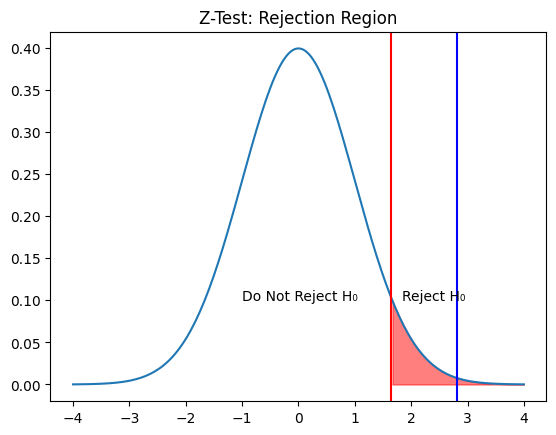

In [ ]:
import matplotlib.pyplot as plt
z = stat
alpha = 0.05
critical_val = norm.ppf(1 - alpha)

x = np.linspace(-4, 4, 200)
y = norm.pdf(x, 0, 1)

plt.plot(x, y)
plt.axvline(critical_val, color='red')
plt.fill_between(x[x > critical_val], y[x > critical_val], color='red', alpha=0.5)
plt.axvline(z, color='blue', label=f'Z = {z:.2f}')
plt.annotate('Reject H₀', (critical_val + 0.2, 0.1))
plt.annotate('Do Not Reject H₀', (-1, 0.1))
plt.title('Z-Test: Rejection Region')
plt.show()

In [ ]:
# Making convertion rate data a binary value
data['converted_binary'] = data['converted'].map({'yes': 1, 'no': 0})

control_group = data[data['group'] == 'control']
treatment_group = data[data['group'] == 'treatment']
n1 = len(control_group)
n2 = len(treatment_group)
x1 = control_group['converted_binary'].sum()
x2 = treatment_group['converted_binary'].sum()

In [ ]:
from statsmodels.stats.proportion import proportions_ztest

count = np.array([x1, x2])
nobs = np.array([n1, n2])
stat, pval = proportions_ztest(count, nobs, alternative='larger')

print("Z-statistic:", stat)
print("p-value:", pval)

Z-statistic: -2.4077170617153842
p-value: 0.9919736917959437


In [ ]:
alpha = 0.05
if pval < alpha and stat > 0:
    print("Reject the null hypothesis")
else:
    print("Fail to reject the null hypothesis")

Fail to reject the null hypothesis


At a 5% significance level we fail to reject the null hypothesis, we do not have sufficient evidence to say the conversion rate of the new page is greater than the old page.

## 3. The conversion and preferred language are independent or related?

H₀: Conversion and preferred language are independent.

Ha: Conversion and preferred language are related.

Since we're checking whether the categorical variables from a population are indeendent, we'll use a Chi-Square Test of Independence.


In [ ]:
#Creating a contingency table to describe the 2 variables at 2 levels each.
from scipy.stats import chi2_contingency

contingency_table = pd.crosstab(data['language_preferred'], data['converted'])
print(contingency_table)


converted           no  yes
language_preferred         
English             11   21
French              19   15
Spanish             16   18


Assumptions:

*   Categorical variables
*   Random sampling
*   Expected value of sample observations in each level of variable is at least 5

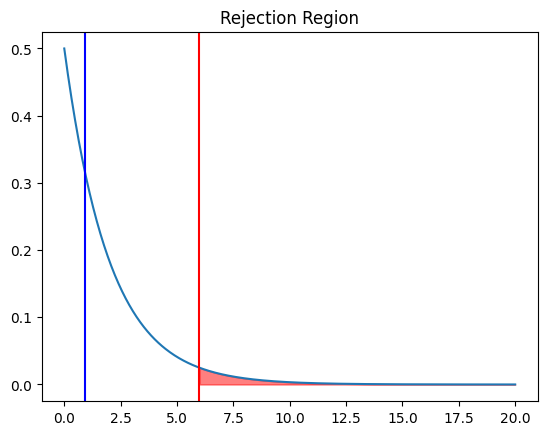

In [ ]:
from scipy.stats import chi2
critical_val = chi2.ppf(1 - alpha, dof)
alpha = 0.05

x = np.linspace(0, 20, 500)
y = chi2.pdf(x, dof)

plt.plot(x, y, label=f'Chi-square dist (df={dof})')
plt.fill_between(x[x > critical_val], y[x > critical_val], color='red', alpha=0.5, label='Rejection Region')

plt.axvline(chi2.sf(p, df=dof), color='blue', label=f'Chi² Stat = {chi2.sf(p, df=dof):.2f}')
plt.axvline(critical_val, color='red', label=f'Critical Value = {critical_val:.2f}')
plt.title('Rejection Region')
plt.show()

In [ ]:
chi2, p, dof, expected = chi2_contingency(contingency_table)

print('Chi-square statistic:', chi2)
print('Degrees of freedom:', dof)
print('P-value:', p)

Chi-square statistic: 3.0930306905370832
Degrees of freedom: 2
P-value: 0.2129888748754345


In [ ]:
alpha = 0.05
if p < alpha:
    print('Reject the null hypothesis')
else:
    print('Fail to reject the null hypothesis')

Fail to reject the null hypothesis


At a 5% significance level, we fail to reject the null hypothesis, meaning that there is no significant relationship between conversion and the preferred language.

## 4. Is the time spent on the new page same for the different language users?

Since we wanto to determine wheter the means of more of 2 independent populations are different we will use a One-Way ANOVA



*   Response : Time spent on the new page
*   Factor : Language

Comparing M of time spent for different languages

*   H0 : μ1 = μ2 = μ3
*   Ha : At least the mean of time spent on the new page for one languaje is different.

Assumptions

*   Population normally distributed
*   Independent random samples
*   Equal population variances



H0 : m1 = m2 = m3
Ha : m1

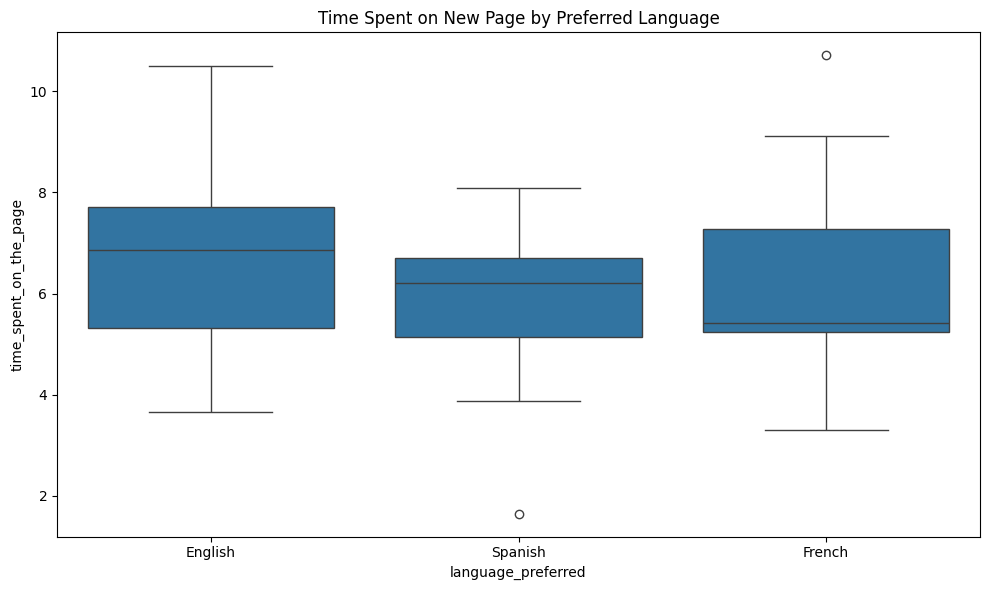

In [ ]:
plt.figure(figsize=(10,6))
sns.boxplot(x='language_preferred', y='time_spent_on_the_page', data=data[data['landing_page'] == 'new'])
plt.title('Time Spent on New Page by Preferred Language')
plt.tight_layout()
plt.show()

We can see from the boxplot that the median of the 3 languajes variates. Spanish and French languaje have odd outliers, however for the 3 languajes 50% of the data lies between 5 and 8 minutes.

In [ ]:
aovdata = data[data['landing_page'] == 'new'].groupby('language_preferred')['time_spent_on_the_page'].mean()
print(aovdata)

language_preferred
English   6.664
French    6.196
Spanish   5.835
Name: time_spent_on_the_page, dtype: float64


We'll start with Shapiro-Wilk test.

*   H0: time spent on the new page follows a normal distribution against alternative hypothesis.
*   Ha: time spent on the new page does not follow a normal distribution.



In [ ]:
#Shapiro-Wilk test
stat, p = stats.shapiro(data[data['landing_page'] == 'new']['time_spent_on_the_page'])
print('Statistics=%.3f, p-value is=%.3f' % (stat, p))


Statistics=0.986, p-value is=0.804


In [ ]:
if p < 0.05:
    print('Reject H0')
else:
    print('Fail to reject H0, time spent on the new page follows a normal distribution')

Fail to reject H0, time spent on the new page follows a normal distribution


We'll do a Levene's test.

*   H0: All population variances are equal against the alternative hypothesis.
*   Ha: At leat one variable is different from the rest.

In [ ]:
from scipy.stats import levene
stat, p = levene(
    data[(data['language_preferred'] == 'English') & (data['landing_page'] == 'new')]['time_spent_on_the_page'],
    data[(data['language_preferred'] == 'Spanish') & (data['landing_page'] == 'new')]['time_spent_on_the_page'],
    data[(data['language_preferred'] == 'French') & (data['landing_page'] == 'new')]['time_spent_on_the_page'])
print('Statistics=%.3f, p-value is=%.3f' % (stat, p))

Statistics=0.774, p-value is=0.467


In [ ]:
if p < 0.05:
    print('Reject H0')
else:
    print('Fail to reject H0, all population variances are equal')

Fail to reject H0, all population variances are equal


In [ ]:
Now we'll calculate the p-value.

In [ ]:
from scipy.stats import f_oneway
ggroups = [data[(data['language_preferred'] == lang) & (data['landing_page'] == 'new')]['time_spent_on_the_page']
    for lang in ['English', 'Spanish', 'French']]
test_stat, p_value = f_oneway(*groups)

print('ANOVA Test: Statistics=%.3f, p-value=%.3f' % (test_stat, p_value))

ANOVA Test: Statistics=0.143, p-value=0.867


In [ ]:
if p_value < 0.05:
    print('Reject H0: Time spent on the landing page differs by language.')
else:
    print('Fail to reject H0: No significant difference in time spent by language.')

Fail to reject H0: No significant difference in time spent by language.


At a 5% level of significance, we fail to reject the H0, there is no significant difference in time spent on the new page per languaje

We'll run a multiple coparison test just to double check if means are different from.

*   H0: μ1=μ2 and μ1=μ3 and μ2=μ3
*   Ha: μ1≠μ2 or μ1≠M3 or μ2≠M3

In [ ]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd
tukey_results = pairwise_tukeyhsd(endog=data[data['landing_page'] == 'new']['time_spent_on_the_page'],
    groups=data[data['landing_page'] == 'new']['language_preferred'],alpha=0.05)
print(tukey_results)

 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
 group1  group2 meandiff p-adj   lower  upper  reject
-----------------------------------------------------
English  French  -0.4673 0.7434 -2.0035  1.069  False
English Spanish  -0.8285 0.3995 -2.3647 0.7078  False
 French Spanish  -0.3612 0.8326  -1.874 1.1516  False
-----------------------------------------------------


As concluded from the previous p-value calculations, the means between the time spent on the page per preferred languaje are the same.

## Conclusion and Business Recommendations


1. Do the users spend more time on the new landing page than the existing
landing page?
*   At a 5% significance level, we reject the null hypothesis,  showing that users spend significantly more time on the new landing page than the existing one.
2. Is the conversion rate (the proportion of users who visit the landing page and get converted) for the new page greater than the conversion rate for the old page?
*   At a 5% significance level we fail to reject the null hypothesis, we do not have sufficient evidence to say the conversion rate of the new page is greater than the old page.
3. The conversion and preferred language are independent or related?
*   At a 5% significance level, we fail to reject the null hypothesis, meaning that there is no significant relationship between conversion and the preferred language.
4. Is the time spent on the new page same for the different language users?
*   At a 5% level of significance, we fail to reject the H0, there is no significant difference in time spent on the new page per languaje

It's a fact that users are spending more time on the new page which indicates that the new strategy worked. I will recommend to analysze deeper the user interaction to identify which elements of the new landing page are contributing to this longer user engagement.
We can also observe that though the users are spending more time on the new landing page, the convertion rate is not increasing significantly, I will advise to investigate deeper the call-to-action design and the user experience with it, to determine what is holding the users to convert or subscribe.
We can confirm that the languaaje doesn't play a role on the convertion rate so this indicates the page languaje is working properly and just keeing an eye on the user's behavior will be enough.
This last point is also backed by the evidence proving that the languaje doesn't influence the users time spent on the page, which proves that overall there is a good translation quality.
With all this, I strongly recommend to analyse the call-to-action of the page to figure out were are users dropping off and what it's keeping them from subscribing.


___